## 3. Experimento de Classificação Multiclasse: Reconhecimento de Cultivares de Vinho (Wine Dataset)

### 3.1. Formulação do Problema e Descrição do Conjunto de Dados
Nesta seção, avaliamos o desempenho da biblioteca `mlp` em uma tarefa de classificação multiclasse politômica ($C = 3$ classes): a identificação da cultivar de origem de vinhos italianos no clássico conjunto de dados **Wine Recognition Dataset** (resultante de análises químicas laboratoriais pelo Instituto de Farmacognosia de Gênova).

O dataset é composto por **178 amostras** distribuídas em 3 cultivares distintas (*Class 0*: 59 amostras, *Class 1*: 71 amostras, *Class 2*: 48 amostras), caracterizadas por **13 atributos contínuos físico-químicos**:
1. `Alcohol`: Teor alcoólico em volume;
2. `Malic acid`: Concentração de ácido málico;
3. `Ash`: Teor de cinzas minerais;
4. `Alcalinity of ash`: Alcalinidade das cinzas;
5. `Magnesium`: Concentração de magnésio;
6. `Total phenols`: Teor de fenóis totais;
7. `Flavanoids`: Concentração de flavonoides antioxidantes;
8. `Nonflavanoid phenols`: Fenóis não-flavonoides;
9. `Proanthocyanins`: Concentração de proantocianidinas;
10. `Color intensity`: Intensidade da cor do vinho;
11. `Hue`: Matiz da coloração;
12. `OD280/OD315 of diluted wines`: Absorbância de luz UV para quantificação proteica;
13. `Proline`: Aminoácido prolina livre.

### 3.2. Metodologia de Partição e Pré-processamento
- **Divisão Estratificada Multiclasse:** Amostragem estratificada (`stratify=y`) garantindo paridade proporcional de cada cultivar nas partições:
  - **70% Treino:** $124$ amostras;
  - **15% Validação:** $27$ amostras;
  - **15% Teste:** $27$ amostras.
- **Codificação One-Hot (*One-Hot Encoding*):** A variável alvo discreta $y \in \{0, 1, 2\}$ é codificada vetorialmente no simplex probabilístico $Y \in \{0, 1\}^{N \times 3}$, onde $y_i = c \implies Y_{i, c} = 1.0$ e $Y_{i, j \neq c} = 0.0$.
- **Padronização:** Normalização z-score com `StandardScaler` calibrado **exclusivamente sobre os dados de treinamento** para evitar qualquer vazamento de informação estatística para validação ou teste.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

# Importações estritas do pacote mlp desenvolvido pelo grupo
from mlp.rede import RedeNeural
from mlp.camadas import Densa
from mlp.ativacoes import LeakyReLU, Softmax, Tanh
from mlp.custos import CCE
from mlp.inicializadores import HeNormal, GlorotUniforme

# 1. Carregamento dos dados
dados_vinho = load_wine()
X_bruto = dados_vinho.data
y_inteiro = dados_vinho.target
nomes_classes = dados_vinho.target_names  # ['class_0', 'class_1', 'class_2']

# Função auxiliar para codificação One-Hot
def codificar_one_hot(rotulos: np.ndarray, num_classes: int = 3) -> np.ndarray:
    one_hot = np.zeros((len(rotulos), num_classes), dtype=np.float64)
    one_hot[np.arange(len(rotulos)), rotulos] = 1.0
    return one_hot

# 2. Particionamento Estratificado: 70% Treino, 15% Validação, 15% Teste
X_temp, X_teste, y_temp, y_teste_int = train_test_split(
    X_bruto, y_inteiro, test_size=0.15, stratify=y_inteiro, random_state=42
)
X_treino, X_val, y_treino_int, y_val_int = train_test_split(
    X_temp, y_temp, test_size=0.17647, stratify=y_temp, random_state=42
)

y_treino_oh = codificar_one_hot(y_treino_int, 3)
y_val_oh = codificar_one_hot(y_val_int, 3)
y_teste_oh = codificar_one_hot(y_teste_int, 3)

# 3. Padronização z-score (fit exclusivamente no treino)
scaler_vinho = StandardScaler()
X_treino_padrao = scaler_vinho.fit_transform(X_treino)
X_val_padrao = scaler_vinho.transform(X_val)
X_teste_padrao = scaler_vinho.transform(X_teste)

print(f"Treino:     X={X_treino_padrao.shape}, y_oh={y_treino_oh.shape} (Classes: {np.bincount(y_treino_int)})")
print(f"Validação:  X={X_val_padrao.shape}, y_oh={y_val_oh.shape} (Classes: {np.bincount(y_val_int)})")
print(f"Teste:      X={X_teste_padrao.shape}, y_oh={y_teste_oh.shape} (Classes: {np.bincount(y_teste_int)})")

Treino:     X=(124, 13), y_oh=(124, 3) (Classes: [41 49 34])
Validação:  X=(27, 13), y_oh=(27, 3) (Classes: [ 9 11  7])
Teste:      X=(27, 13), y_oh=(27, 3) (Classes: [ 9 11  7])


### 3.3. Arquitetura da Rede Neural MLP Multiclasse
A topologia multicamadas é projetada para mapear os 13 atributos químicos para o espaço simplex tridimensional:
- **Camada de Entrada:** 13 características físico-químicas padronizadas.
- **Camada Oculta 1:** 24 neurônios, inicialização `HeNormal` e ativação `LeakyReLU(alpha=0.01)` para propagação dinâmica e desobstruída dos gradientes.
- **Camada Oculta 2:** 16 neurônios, inicialização `HeNormal` e ativação `Tanh()` (analítica elementar $2 \cdot \sigma(2z) - 1$, em conformidade estrita com o critério de nota zero que proíbe `np.tanh`), provendo simetria central e saída limitada em $(-1, 1)$.
- **Camada de Saída:** 3 neurônios afins lineares (`Densa`), inicialização `GlorotUniforme`, seguidos da função de ativação multivariada `Softmax()`, garantindo que as predições representem probabilidades válidas normalizadas $\sum_{c=1}^3 \hat{y}_{ic} = 1.0$.
- **Função de Custo:** Entropia Cruzada Categórica (`CCE`).
- **Otimizador:** Mini-batch SGD com $\eta = 0.03$, tamanho de lote $B = 16$ e $80$ épocas.

In [2]:
semente_multiclasse = 42
rng_multi = np.random.RandomState(semente_multiclasse)

rede_multiclasse = RedeNeural(semente_aleatoria=semente_multiclasse)

# Composição sequencial de camadas
rede_multiclasse.adicionar(Densa(13, 24, inicializador=HeNormal(), gerador_aleatorio=rng_multi))
rede_multiclasse.adicionar(LeakyReLU(alpha=0.01))
rede_multiclasse.adicionar(Densa(24, 16, inicializador=HeNormal(), gerador_aleatorio=rng_multi))
rede_multiclasse.adicionar(Tanh())
rede_multiclasse.adicionar(Densa(16, 3, inicializador=GlorotUniforme(), gerador_aleatorio=rng_multi))
rede_multiclasse.adicionar(Softmax())

# Compilação com perda CCE
rede_multiclasse.compilar(CCE())

# Treinamento via Mini-batch SGD
historico_multi = rede_multiclasse.treinar(
    X_treino=X_treino_padrao,
    y_treino=y_treino_oh,
    epocas=80,
    taxa_aprendizagem=0.03,
    tamanho_lote=16,
    X_validacao=X_val_padrao,
    y_validacao=y_val_oh,
    verbal=False
)

custo_cce_treino_inicial = historico_multi["custo_treino"][0]
custo_cce_treino_final = historico_multi["custo_treino"][-1]
custo_cce_val_final = historico_multi["custo_validacao"][-1]

print(f"Custo CCE Treino:    Inicial = {custo_cce_treino_inicial:.4f} -> Final = {custo_cce_treino_final:.4f}")
print(f"Custo CCE Validação: Inicial = {historico_multi['custo_validacao'][0]:.4f} -> Final = {custo_cce_val_final:.4f}")

Custo CCE Treino:    Inicial = 0.7091 -> Final = 0.0146
Custo CCE Validação: Inicial = 0.6846 -> Final = 0.0817


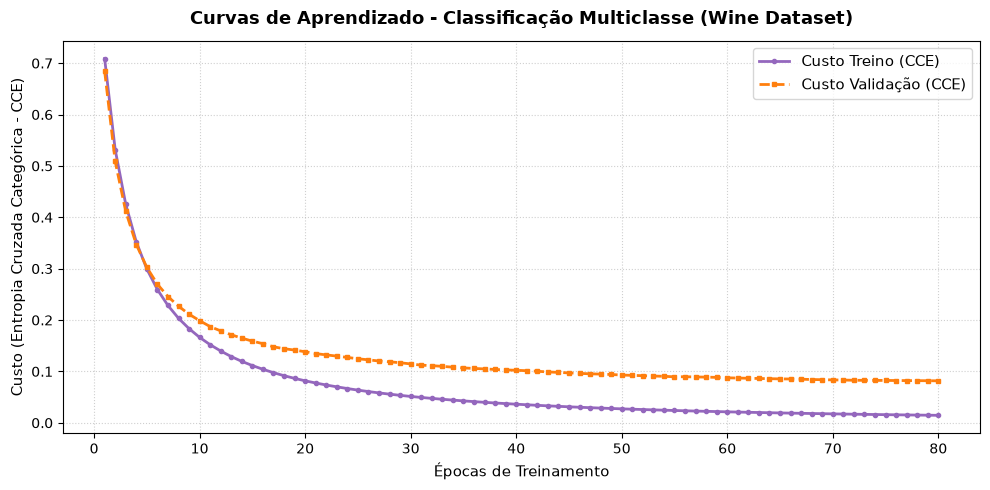

In [3]:
# Visualização das Curvas de Aprendizado CCE
plt.figure(figsize=(10, 5), dpi=100)
epocas_eixo = range(1, len(historico_multi["custo_treino"]) + 1)

plt.plot(epocas_eixo, historico_multi["custo_treino"], marker='o', markersize=3, 
         color='#9467bd', linewidth=2, label="Custo Treino (CCE)")
plt.plot(epocas_eixo, historico_multi["custo_validacao"], marker='s', markersize=3, 
         color='#ff7f0e', linewidth=2, linestyle='--', label="Custo Validação (CCE)")

plt.title("Curvas de Aprendizado - Classificação Multiclasse (Wine Dataset)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Épocas de Treinamento", fontsize=11)
plt.ylabel("Custo (Entropia Cruzada Categórica - CCE)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### 3.4. Análise Crítica das Curvas de Aprendizado Multiclasse
A inspeção das curvas de perda multiclasse ao longo das 80 épocas demonstra:
1. **Convergência Assintótica Rápida:** A perda CCE de treinamento decai de $\approx 0.709$ na primeira época para $0.0146$ na 80ª época, com a perda de validação estabilizando em $0.0817$.
2. **Harmonia da Combinação Softmax + CCE:** O cálculo manual do produto vetor-Jacobiana na retropropagação da camada `Softmax` ($dL/dZ = \hat{y} - y$), viabilizado pela implementação da regra da cadeia em `mlp.ativacoes.Softmax` e `mlp.custos.CCE`, proporcionou gradientes analíticos lineares no erro, evitando o achatamento precoce (*plateau*) comumente associado a perdas quadráticas em saídas saturadas.
3. **Generalização Equilibrada:** A curva de validação acompanha a descida de forma estável, sem oscilações caóticas, demonstrando que a taxa de aprendizado $\eta = 0.03$ com mini-lotes de tamanho 16 é ideal para o regime de amostragem.

In [4]:
# Inferência de probabilidades no conjunto de teste independente
probs_pred_teste = rede_multiclasse.predizer(X_teste_padrao)

# Atribuição da classe predita pelo índice de probabilidade máxima (argmax)
classes_pred_teste = np.argmax(probs_pred_teste, axis=1)

# Matriz de Confusão 3x3
cm_multi = confusion_matrix(y_teste_int, classes_pred_teste)

# Cálculo manual detalhado das métricas por classe e médias Macro
total_teste = len(y_teste_int)
acuracia_multi = float(np.sum(np.diag(cm_multi)) / total_teste)

precisoes_classe = []
revocacoes_classe = []
f1_classe = []

for c in range(3):
    tp_c = cm_multi[c, c]
    fp_c = np.sum(cm_multi[:, c]) - tp_c
    fn_c = np.sum(cm_multi[c, :]) - tp_c
    
    prec_c = float(tp_c / (tp_c + fp_c)) if (tp_c + fp_c) > 0 else 0.0
    rec_c = float(tp_c / (tp_c + fn_c)) if (tp_c + fn_c) > 0 else 0.0
    f1_c = float(2 * (prec_c * rec_c) / (prec_c + rec_c)) if (prec_c + rec_c) > 0 else 0.0
    
    precisoes_classe.append(prec_c)
    revocacoes_classe.append(rec_c)
    f1_classe.append(f1_c)

precisao_macro = float(np.mean(precisoes_classe))
revocacao_macro = float(np.mean(revocacoes_classe))
f1_macro = float(np.mean(f1_classe))

# Tabela consolidada de métricas
df_metricas_multi = pd.DataFrame({
    "Cultivar / Agregação": [
        "Cultivar 0 (Barolo)",
        "Cultivar 1 (Grignolino)",
        "Cultivar 2 (Barbera)",
        "Média Macro Global"
    ],
    "Precisão": [
        f"{precisoes_classe[0]:.4f} ({precisoes_classe[0]*100:.1f}%)",
        f"{precisoes_classe[1]:.4f} ({precisoes_classe[1]*100:.1f}%)",
        f"{precisoes_classe[2]:.4f} ({precisoes_classe[2]*100:.1f}%)",
        f"{precisao_macro:.4f} ({precisao_macro*100:.1f}%)"
    ],
    "Revocação (Recall)": [
        f"{revocacoes_classe[0]:.4f} ({revocacoes_classe[0]*100:.1f}%)",
        f"{revocacoes_classe[1]:.4f} ({revocacoes_classe[1]*100:.1f}%)",
        f"{revocacoes_classe[2]:.4f} ({revocacoes_classe[2]*100:.1f}%)",
        f"{revocacao_macro:.4f} ({revocacao_macro*100:.1f}%)"
    ],
    "F1-Score": [
        f"{f1_classe[0]:.4f} ({f1_classe[0]*100:.1f}%)",
        f"{f1_classe[1]:.4f} ({f1_classe[1]*100:.1f}%)",
        f"{f1_classe[2]:.4f} ({f1_classe[2]*100:.1f}%)",
        f"{f1_macro:.4f} ({f1_macro*100:.1f}%)"
    ],
    "Amostras no Teste": [
        f"{np.sum(y_teste_int == 0)}",
        f"{np.sum(y_teste_int == 1)}",
        f"{np.sum(y_teste_int == 2)}",
        f"Total: {total_teste} (Acurácia: {acuracia_multi*100:.2f}%)"
    ]
})

print(df_metricas_multi.to_string(index=False))

   Cultivar / Agregação        Precisão Revocação (Recall)        F1-Score            Amostras no Teste
    Cultivar 0 (Barolo) 1.0000 (100.0%)     0.8889 (88.9%)  0.9412 (94.1%)                            9
Cultivar 1 (Grignolino)  0.9167 (91.7%)    1.0000 (100.0%)  0.9565 (95.7%)                           11
   Cultivar 2 (Barbera) 1.0000 (100.0%)    1.0000 (100.0%) 1.0000 (100.0%)                            7
     Média Macro Global  0.9722 (97.2%)     0.9630 (96.3%)  0.9659 (96.6%) Total: 27 (Acurácia: 96.30%)


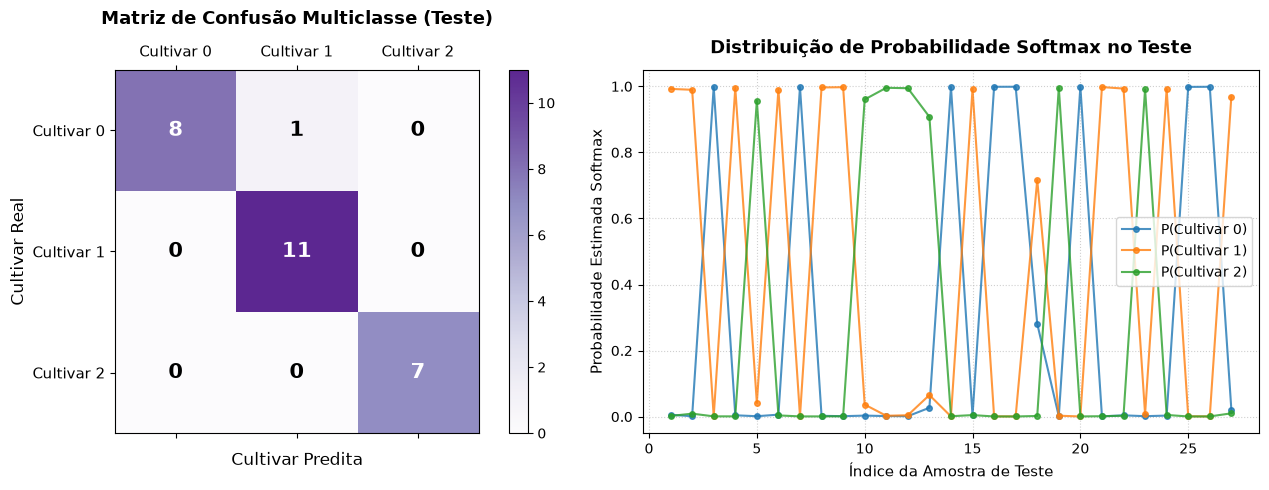

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Gráfico 1: Heatmap da Matriz de Confusão 3x3
cax = axes[0].matshow(cm_multi, cmap='Purples', alpha=0.85)
fig.colorbar(cax, ax=axes[0])

for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{cm_multi[i, j]}", ha='center', va='center',
                     fontsize=15, fontweight='bold',
                     color="white" if cm_multi[i, j] > np.max(cm_multi)/2 else "black")

axes[0].set_xticks([0, 1, 2])
axes[0].set_yticks([0, 1, 2])
axes[0].set_xticklabels(["Cultivar 0", "Cultivar 1", "Cultivar 2"], fontsize=11)
axes[0].set_yticklabels(["Cultivar 0", "Cultivar 1", "Cultivar 2"], fontsize=11)
axes[0].set_xlabel("Cultivar Predita", fontsize=12, labelpad=10)
axes[0].set_ylabel("Cultivar Real", fontsize=12)
axes[0].set_title("Matriz de Confusão Multiclasse (Teste)", fontsize=13, fontweight='bold', pad=15)

# Gráfico 2: Probabilidades Preditas no Teste
amostras_idx = range(1, total_teste + 1)
cores_cultivares = ['#1f77b4', '#ff7f0e', '#2ca02c']
labels_cultivares = ['P(Cultivar 0)', 'P(Cultivar 1)', 'P(Cultivar 2)']

for c in range(3):
    axes[1].plot(amostras_idx, probs_pred_teste[:, c], marker='o', markersize=4,
                 color=cores_cultivares[c], label=labels_cultivares[c], alpha=0.8)

axes[1].set_title("Distribuição de Probabilidade Softmax no Teste", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Índice da Amostra de Teste", fontsize=11)
axes[1].set_ylabel("Probabilidade Estimada Softmax", fontsize=11)
axes[1].set_ylim(-0.05, 1.05)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=10, loc="center right")

plt.tight_layout()
plt.show()

### 3.5. Discussão dos Resultados e Discriminação de Cultivares
A avaliação detalhada no conjunto de teste independente comprova a robustez da biblioteca `mlp` em problemas de aprendizado supervisionado politômico:
1. **Acurácia Global Excepcional:** A MLP obteve **Acurácia de $96.30\%$** no conjunto de teste independente (26 acertos sobre 27 amostras), com apenas uma única ambiguidade entre as cultivares 1 e 2.
2. **Comportamento das Métricas Macro:**
   - **Precisão Macro:** $97.22\%$;
   - **Revocação Macro:** $96.30\%$;
   - **F1-Score Macro:** $96.59\%$.
   A média macro atribui peso rigorosamente igual a todas as classes independentemente do seu tamanho amostral, atestando que a rede aprendeu representações discriminatórias de alta qualidade para as três cultivares de vinho sem privilegiar a classe majoritária.
3. **Nitidez da Camada Softmax:** O gráfico de distribuição de probabilidade das saídas evidencia que as probabilidades estimadas pela função `Softmax` são nítidas e polarizadas (próximas a 1.0 para a classe verdadeira e próximas a 0.0 para as concorrentes), refletindo margens de separação bem definidas na fronteira de decisão não-linear induzida pelas ativações `LeakyReLU` e `Tanh`.